# Supplementary Figure S11 — amphibole Mg#

Standalone, function-free workflow using only the published Supplement 1 `Transects` and `Mingled_Minerals` sheets. No outside code or unpublished data are required.

Mg# is calculated using **total iron reported as FeOₜ**, not Fe²⁺ alone:

`Mg# = 100 × (MgO/40.3044) / [(MgO/40.3044) + (FeOₜ/71.844)]`

## Shared setup for Figure S11

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Patch
from IPython.display import display

DECHERT_DATA_DIRECTORY = Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20')
USER_DATA_DIRECTORY = Path('/replace/with/your/folder/containing/the/three/supplemental/files')
DATA_DIRECTORY = DECHERT_DATA_DIRECTORY
# DATA_DIRECTORY = USER_DATA_DIRECTORY

PROJECT_ROOT = None
for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if candidate.name == 'Nov6_AllFigures':
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start in Nov6_AllFigures or one of its figure folders.')

FIGURE_DIRECTORY = PROJECT_ROOT / 'Figure_S11_Amph_Mg_Number'
OUTPUT_DIRECTORY = FIGURE_DIRECTORY / 'Figure_S11_Amph_Mg_Number_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
WORKBOOK_PATHS = {
    'S1': DATA_DIRECTORY / 'Dechert_S1_AllData.xlsx',
    'S2': DATA_DIRECTORY / 'Dechert_S2_Standards.xlsx',
    'S3': DATA_DIRECTORY / 'Dechert_S3_Compilations.xlsx',
}
for supplement, path in WORKBOOK_PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f'{supplement}: required supplemental file not found: {path}')

SINGLE_COLUMN_WIDTH_IN = 3.55
DOUBLE_COLUMN_WIDTH_IN = 7.25
MAXIMUM_RECOMMENDED_HEIGHT_IN = 7.8
FIGURE_WIDTH_IN = DOUBLE_COLUMN_WIDTH_IN
FIGURE_HEIGHT_IN = 3.50
BASE_TEXT_SIZE_PT = 8.0
PANEL_LABEL_SIZE_PT = 9.0
SMALL_ANNOTATION_SIZE_PT = 6.0
MINIMUM_LINE_WIDTH_PT = 0.28
EXPORT_DPI = 300

PUBLICATION_FONT = 'Arial'
if PUBLICATION_FONT not in {entry.name for entry in font_manager.fontManager.ttflist}:
    raise RuntimeError('Arial is required. Install Arial and restart Python.')
PUBLICATION_FONT_PATH = font_manager.findfont(PUBLICATION_FONT, fallback_to_default=False)
mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': [PUBLICATION_FONT], 'font.size': 8.0,
    'axes.labelsize': 8.0, 'axes.titlesize': 8.0, 'xtick.labelsize': 8.0,
    'ytick.labelsize': 8.0, 'legend.fontsize': 8.0, 'legend.title_fontsize': 8.0,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'axes.spines.top': True,
    'axes.spines.right': True, 'axes.linewidth': 0.5, 'lines.linewidth': 0.75,
    'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.major.width': 0.5,
    'ytick.major.width': 0.5, 'savefig.facecolor': 'white', 'savefig.transparent': False,
    'mathtext.fontset': 'custom', 'mathtext.rm': PUBLICATION_FONT,
    'mathtext.it': f'{PUBLICATION_FONT}:italic', 'mathtext.bf': f'{PUBLICATION_FONT}:bold',
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
})

SAMPLE_MEMBERS = {'B': ['74D', '74A'], 'G': ['75', '76A']}
SAMPLE_ORDER = ['B', 'G']
LINE_COLORMAPS = {'B': 'Oranges', 'G': 'Blues'}
HISTOGRAM_COLORS = {'B': '#F4A261', 'G': '#56B4E9'}
MINGLED_DATASETS = {'B': '74Ming', 'G': '76Ming'}
MINGLED_COLORS = {'B': {'light': '#EE3377', 'dark': '#808080'}, 'G': {'light': '#66C2C2', 'dark': '#000000'}}
TEXTURE_LABELS = {'Felsic': 'light', 'Mafic': 'dark', 'light': 'light', 'dark': 'dark'}
PREDICTION_SCORE_MIN = 0.85
DOMINANT_MINERAL_FRACTION_MIN = 0.95
HISTOGRAM_OVERSAMPLE_MULTIPLIER = 10
N_HISTOGRAM_EDGES = 20
MG_O_MOLAR_MASS = 40.3044
FE_O_MOLAR_MASS = 71.844

print('Figure directory:', FIGURE_DIRECTORY)
print('Publication font:', PUBLICATION_FONT_PATH)
print('Figure dimensions:', FIGURE_WIDTH_IN, 'x', FIGURE_HEIGHT_IN, 'in')

Figure directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S11_Amph_Mg_Number
Publication font: /System/Library/Fonts/Supplemental/Arial.ttf
Figure dimensions: 7.25 x 3.5 in


## Figure S11-specific data preparation

The shared setup ends above. The code below reads only the two required Supplement 1 sheets, identifies qualifying amphibole transects, and calculates Mg# directly from raw MgO and FeOₜ for both datasets.

In [2]:
transect_source = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Transects').rename(columns={'Sample': 'Sample_Group'})
mingled_source = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Mingled_Minerals').rename(columns={'Type of Pumice': 'Mafic/Felsic'})

# Determine the dominant predicted mineral for each complete transect.
scan_counts = transect_source.groupby(['Linescan_ID', 'Predict_Mineral'], dropna=False).size().rename('count').reset_index()
scan_counts = scan_counts.sort_values(['Linescan_ID', 'count', 'Predict_Mineral'], ascending=[True, False, True])
dominant_rows = scan_counts.drop_duplicates('Linescan_ID').set_index('Linescan_ID')
scan_totals = transect_source.groupby('Linescan_ID').size()
transect_source['Dominant_Mineral'] = transect_source['Linescan_ID'].map(dominant_rows['Predict_Mineral'])
transect_source['Dominant_Mineral_Fraction'] = transect_source['Linescan_ID'].map(dominant_rows['count'].div(scan_totals))

# Calculate Mg# from total iron reported as FeOt.
transect_mg_moles = pd.to_numeric(transect_source['MgO_SEMMineral_Raw'], errors='coerce') / MG_O_MOLAR_MASS
transect_fe_moles = pd.to_numeric(transect_source['FeOt_SEMMineral_Raw'], errors='coerce') / FE_O_MOLAR_MASS
transect_source['Mg_number_FeOt'] = 100 * transect_mg_moles / (transect_mg_moles + transect_fe_moles)
reported_mg_number = pd.to_numeric(transect_source['Mg#'], errors='coerce')
comparable = reported_mg_number.notna() & transect_source['Mg_number_FeOt'].notna()
maximum_difference = (reported_mg_number[comparable] - transect_source.loc[comparable, 'Mg_number_FeOt']).abs().max()
print('Maximum difference from supplied transect Mg#:', maximum_difference)

transect_source['_distance_um'] = pd.to_numeric(transect_source['Distance (µm)'], errors='coerce')
transect_source['_prediction_score'] = pd.to_numeric(transect_source['Prediction_Score'], errors='coerce')
transect_source['_dominant_fraction'] = pd.to_numeric(transect_source['Dominant_Mineral_Fraction'], errors='coerce')
standard_name_pattern = r'(?:albite|kl_?2g?|macfo|anorthite|labradorite|lab\d)'
is_standard = transect_source['Source_CSV'].astype('string').str.contains(standard_name_pattern, case=False, na=False, regex=True)
is_discarded = pd.Series(False, index=transect_source.index)
for discard_column in ['discard', 'Discard']:
    if discard_column in transect_source.columns:
        discard_text = transect_source[discard_column].astype('string').str.strip().str.casefold()
        is_discarded |= discard_text.isin(['1', 'true', 'yes', 'y', 'discard', 'discarded']).fillna(False)

all_samples = SAMPLE_MEMBERS['B'] + SAMPLE_MEMBERS['G']
amphibole_mask = ~is_standard & ~is_discarded
amphibole_mask &= transect_source['Sample_Group'].isin(all_samples)
amphibole_mask &= transect_source['Dominant_Mineral'].astype('string').str.strip().str.casefold().eq('amphibole')
amphibole_mask &= transect_source['_dominant_fraction'].ge(DOMINANT_MINERAL_FRACTION_MIN)
amphibole_mask &= transect_source['Predict_Mineral'].astype('string').str.strip().str.casefold().eq('amphibole')
amphibole_mask &= transect_source['_prediction_score'].gt(PREDICTION_SCORE_MIN)
amphibole_mask &= transect_source['_distance_um'].notna() & transect_source['Mg_number_FeOt'].notna()
amphibole_points = transect_source.loc[amphibole_mask].copy()

# Every transect receives the same number of interpolated values so long scans do not dominate histograms.
valid_nonstandard = ~is_standard & ~is_discarded
maximum_original_points = int(transect_source.loc[valid_nonstandard].groupby('Linescan_ID')['_distance_um'].count().max())
N_INTERPOLATED_VALUES_PER_TRANSECT = maximum_original_points * HISTOGRAM_OVERSAMPLE_MULTIPLIER
AMPHIBOLE_TRANSECTS = {}
EQUAL_WEIGHT_MG_NUMBERS = {}
for sample_pool in SAMPLE_ORDER:
    pool_transects = []
    interpolated_profiles = []
    for sample in SAMPLE_MEMBERS[sample_pool]:
        sample_points = amphibole_points.loc[amphibole_points['Sample_Group'].eq(sample)]
        for linescan_id, transect in sample_points.groupby('Linescan_ID', sort=True):
            plotted = transect.sort_values(['_distance_um', 'Point_Order'], kind='stable').copy()
            plotted.attrs['linescan_id'] = linescan_id
            plotted.attrs['sample_group'] = sample
            pool_transects.append(plotted)
            xy = plotted[['_distance_um', 'Mg_number_FeOt']].rename(columns={'_distance_um': 'x', 'Mg_number_FeOt': 'y'}).dropna()
            xy = xy.groupby('x', as_index=False)['y'].mean().sort_values('x')
            if len(xy) == 1:
                interpolated = np.repeat(float(xy['y'].iloc[0]), N_INTERPOLATED_VALUES_PER_TRANSECT)
            else:
                profile_position = np.linspace(0.0, 1.0, len(xy))
                target_position = np.linspace(0.0, 1.0, N_INTERPOLATED_VALUES_PER_TRANSECT)
                interpolated = np.interp(target_position, profile_position, xy['y'].to_numpy(float))
            interpolated_profiles.append(interpolated)
    AMPHIBOLE_TRANSECTS[sample_pool] = pool_transects
    EQUAL_WEIGHT_MG_NUMBERS[sample_pool] = np.concatenate(interpolated_profiles)

# Mingled-pumice amphiboles use the same FeOt-based equation.
mingled_prediction_score = pd.to_numeric(mingled_source['Prediction_Score'], errors='coerce')
mingled_mask = mingled_source['Predict_Mineral'].astype('string').str.strip().str.casefold().eq('amphibole')
mingled_mask &= mingled_prediction_score.gt(PREDICTION_SCORE_MIN)
mingled_amphiboles = mingled_source.loc[mingled_mask].copy()
mingled_mg_moles = pd.to_numeric(mingled_amphiboles['MgO_SEMMineral_Raw'], errors='coerce') / MG_O_MOLAR_MASS
mingled_fe_moles = pd.to_numeric(mingled_amphiboles['FeOt_SEMMineral_Raw'], errors='coerce') / FE_O_MOLAR_MASS
mingled_amphiboles['Mg_number_FeOt'] = 100 * mingled_mg_moles / (mingled_mg_moles + mingled_fe_moles)
mingled_amphiboles['display_texture'] = mingled_amphiboles['Mafic/Felsic'].map(TEXTURE_LABELS)
mingled_amphiboles = mingled_amphiboles.dropna(subset=['Dataset', 'display_texture', 'Mg_number_FeOt'])
MINGLED_MG_NUMBERS = {}
for sample_pool in SAMPLE_ORDER:
    MINGLED_MG_NUMBERS[sample_pool] = {}
    for texture in ['light', 'dark']:
        selection = mingled_amphiboles['Dataset'].astype('string').eq(MINGLED_DATASETS[sample_pool]) & mingled_amphiboles['display_texture'].eq(texture)
        MINGLED_MG_NUMBERS[sample_pool][texture] = mingled_amphiboles.loc[selection, 'Mg_number_FeOt'].to_numpy(float)

print('Equal weighting:', N_INTERPOLATED_VALUES_PER_TRANSECT, 'interpolated values per transect')
print('Mg# calculation uses total iron as FeOt for both source sheets.')

Maximum difference from supplied transect Mg#: 2.842170943040401e-14
Equal weighting: 11200 interpolated values per transect
Mg# calculation uses total iron as FeOt for both source sheets.


## Shared Mg# scale and cohort summary

In [3]:
all_mg_number_arrays = []
for sample_pool in SAMPLE_ORDER:
    all_mg_number_arrays.append(EQUAL_WEIGHT_MG_NUMBERS[sample_pool])
    all_mg_number_arrays.append(MINGLED_MG_NUMBERS[sample_pool]['light'])
    all_mg_number_arrays.append(MINGLED_MG_NUMBERS[sample_pool]['dark'])
mg_number_minimum = min(float(np.nanmin(values)) for values in all_mg_number_arrays)
mg_number_maximum = max(float(np.nanmax(values)) for values in all_mg_number_arrays)
MG_NUMBER_BINS = np.linspace(mg_number_minimum, mg_number_maximum, N_HISTOGRAM_EDGES)
MG_NUMBER_AXIS_LIMITS = (mg_number_minimum, mg_number_maximum)
TRANSECT_HISTOGRAM_XMAX = max(np.histogram(EQUAL_WEIGHT_MG_NUMBERS[sample_pool], bins=MG_NUMBER_BINS)[0].max() for sample_pool in SAMPLE_ORDER) * 1.05
MINGLED_HISTOGRAM_XMAX = max(np.histogram(MINGLED_MG_NUMBERS[sample_pool][texture], bins=MG_NUMBER_BINS)[0].max() for sample_pool in SAMPLE_ORDER for texture in ['light', 'dark']) * 1.05
summary_rows = []
for sample_pool in SAMPLE_ORDER:
    transects = AMPHIBOLE_TRANSECTS[sample_pool]
    transect_values = EQUAL_WEIGHT_MG_NUMBERS[sample_pool]
    light_values = MINGLED_MG_NUMBERS[sample_pool]['light']
    dark_values = MINGLED_MG_NUMBERS[sample_pool]['dark']
    summary_rows.append({
        'sample_pool': sample_pool,
        'n_transects': len(transects),
        'n_linescan_points': sum(len(frame) for frame in transects),
        'transect_median': np.median(transect_values),
        'n_mingled_light': len(light_values),
        'mingled_light_median': np.median(light_values),
        'n_mingled_dark': len(dark_values),
        'mingled_dark_median': np.median(dark_values),
    })
cohort_summary = pd.DataFrame(summary_rows)
display(cohort_summary)

,sample_pool,n_transects,n_linescan_points,transect_median,n_mingled_light,mingled_light_median,n_mingled_dark,mingled_dark_median
0,B,22,702,68.608800,35,68.291307,20,66.032796
1,G,11,936,68.927995,21,68.243873,15,69.814746


## Plot and export Figure S11

Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S11_Amph_Mg_Number/Figure_S11_Amph_Mg_Number_Final/Figure_S11_Amph_Mg_Number.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S11_Amph_Mg_Number/Figure_S11_Amph_Mg_Number_Final/Figure_S11_Amph_Mg_Number.png
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S11_Amph_Mg_Number/Figure_S11_Amph_Mg_Number_Final/Figure_S11_Amph_Mg_Number.svg


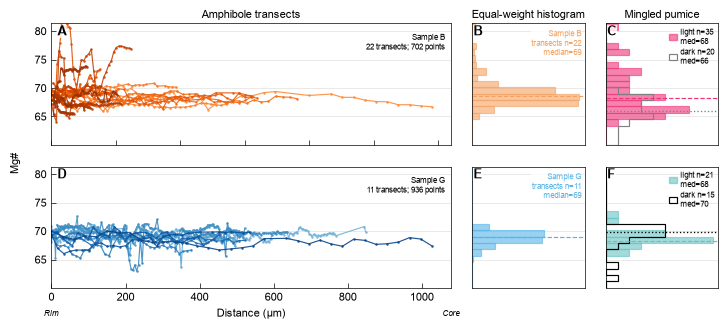

In [4]:
figure = plt.figure(figsize=(FIGURE_WIDTH_IN, FIGURE_HEIGHT_IN))
grid = figure.add_gridspec(2, 3, width_ratios=(4.6, 1.30, 1.30), wspace=0.10, hspace=0.18)
axes = np.empty((2, 3), dtype=object)
panel_letters = list('ABCDEF')
panel_index = 0

for row_index, sample_pool in enumerate(SAMPLE_ORDER):
    line_axis = figure.add_subplot(grid[row_index, 0])
    histogram_axis = figure.add_subplot(grid[row_index, 1], sharey=line_axis)
    mingled_axis = figure.add_subplot(grid[row_index, 2], sharey=line_axis)
    axes[row_index] = (line_axis, histogram_axis, mingled_axis)

    transects = AMPHIBOLE_TRANSECTS[sample_pool]
    line_colormap = plt.colormaps[LINE_COLORMAPS[sample_pool]]
    color_positions = np.linspace(0.48, 0.92, max(len(transects), 2))
    for transect_index, transect in enumerate(transects):
        line_axis.plot(transect['_distance_um'].to_numpy(float), transect['Mg_number_FeOt'].to_numpy(float), '-o', color=line_colormap(color_positions[transect_index]), linewidth=0.85, markersize=1.80, markeredgewidth=0.0, alpha=0.90, zorder=2)

    transect_values = EQUAL_WEIGHT_MG_NUMBERS[sample_pool]
    transect_median = float(np.median(transect_values))
    transect_color = HISTOGRAM_COLORS[sample_pool]
    histogram_axis.hist(transect_values, bins=MG_NUMBER_BINS, orientation='horizontal', color=transect_color, edgecolor=transect_color, alpha=0.60, linewidth=0.85)
    histogram_axis.axhline(transect_median, color=transect_color, linestyle='--', linewidth=0.85)
    histogram_axis.text(0.97, 0.95, f'Sample {sample_pool}\ntransects n={len(transects)}\nmedian={transect_median:.0f}', transform=histogram_axis.transAxes, ha='right', va='top', fontsize=SMALL_ANNOTATION_SIZE_PT, color=transect_color, bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.78, 'pad': 0.5}, zorder=10)

    light_values = MINGLED_MG_NUMBERS[sample_pool]['light']
    dark_values = MINGLED_MG_NUMBERS[sample_pool]['dark']
    light_median = float(np.median(light_values))
    dark_median = float(np.median(dark_values))
    light_color = MINGLED_COLORS[sample_pool]['light']
    dark_color = MINGLED_COLORS[sample_pool]['dark']
    mingled_axis.hist(light_values, bins=MG_NUMBER_BINS, orientation='horizontal', color=light_color, edgecolor=light_color, alpha=0.60, linewidth=0.85)
    mingled_axis.hist(dark_values, bins=MG_NUMBER_BINS, orientation='horizontal', histtype='step', color=dark_color, linewidth=0.85)
    mingled_axis.axhline(light_median, color=light_color, linestyle='--', linewidth=0.85)
    mingled_axis.axhline(dark_median, color=dark_color, linestyle=':', linewidth=0.95)
    mingled_axis.legend(handles=[Patch(facecolor=light_color, edgecolor=light_color, alpha=0.60, label=f'light n={len(light_values)}\nmed={light_median:.0f}'), Patch(facecolor='none', edgecolor=dark_color, linewidth=0.85, label=f'dark n={len(dark_values)}\nmed={dark_median:.0f}')], loc='upper right', fontsize=SMALL_ANNOTATION_SIZE_PT, frameon=False, borderpad=0.0, labelspacing=0.18, handlelength=1.0, handletextpad=0.35)

    for axis in [line_axis, histogram_axis, mingled_axis]:
        axis.set_ylim(*MG_NUMBER_AXIS_LIMITS)
        axis.grid(axis='y', color='#D9D9D9', linewidth=0.4)
        axis.set_axisbelow(True)
        for spine in axis.spines.values():
            spine.set_visible(True)
            spine.set_color('black')
            spine.set_linewidth(0.50)
        axis.text(0.015, 0.985, panel_letters[panel_index], transform=axis.transAxes, ha='left', va='top', fontsize=PANEL_LABEL_SIZE_PT, fontweight='bold', bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.82, 'pad': 0.35}, zorder=20)
        panel_index += 1

    line_axis.set_xlim(left=0)
    line_axis.text(0.985, 0.92, f'Sample {sample_pool}\n{len(transects)} transects; {sum(len(frame) for frame in transects):,} points', transform=line_axis.transAxes, ha='right', va='top', fontsize=SMALL_ANNOTATION_SIZE_PT, bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.78, 'pad': 0.8}, zorder=10)
    line_axis.ticklabel_format(axis='x', style='plain', useOffset=False)
    histogram_axis.set_xlim(0, TRANSECT_HISTOGRAM_XMAX)
    mingled_axis.set_xlim(0, MINGLED_HISTOGRAM_XMAX)
    for distribution_axis in [histogram_axis, mingled_axis]:
        distribution_axis.tick_params(axis='y', left=False, right=False, labelleft=False, labelright=False)
        distribution_axis.tick_params(axis='x', bottom=False, top=False, labelbottom=False, labeltop=False)

    if row_index == 0:
        line_axis.set_title('Amphibole transects', pad=4)
        histogram_axis.set_title('Equal-weight histogram', pad=4)
        mingled_axis.set_title('Mingled pumice', pad=4)
        line_axis.tick_params(axis='x', labelbottom=False)
    else:
        line_axis.set_xlabel('Distance (µm)')
        x_minimum, x_maximum = line_axis.get_xlim()
        line_axis.annotate('Rim', xy=(x_minimum, 0), xycoords=('data', 'axes fraction'), xytext=(0, -16), textcoords='offset points', ha='center', va='top', fontsize=SMALL_ANNOTATION_SIZE_PT, fontstyle='italic')
        line_axis.annotate('Core', xy=(x_maximum, 0), xycoords=('data', 'axes fraction'), xytext=(0, -16), textcoords='offset points', ha='center', va='top', fontsize=SMALL_ANNOTATION_SIZE_PT, fontstyle='italic')

figure.text(0.022, 0.50, 'Mg#', rotation='vertical', ha='center', va='center', fontsize=8.0)
figure.subplots_adjust(left=0.072, right=0.992, bottom=0.145, top=0.90)

pdf_path = OUTPUT_DIRECTORY / 'Figure_S11_Amph_Mg_Number.pdf'
png_path = OUTPUT_DIRECTORY / 'Figure_S11_Amph_Mg_Number.png'
svg_path = OUTPUT_DIRECTORY / 'Figure_S11_Amph_Mg_Number.svg'
figure.savefig(pdf_path, format='pdf', facecolor='white', transparent=False)
figure.savefig(png_path, format='png', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(svg_path, format='svg', facecolor='white', transparent=False)
print('Saved:', pdf_path)
print('Saved:', png_path)
print('Saved:', svg_path)
plt.show()